### Model architecture

In [1]:
import torch
import torch.nn as nn
from torch.nn.utils.rnn import pack_padded_sequence

In [2]:
data = torch.load(
    "../data/rnn_data.pt",
    weights_only=False
)

In [3]:
X_train_tensor = data["X_train"]
X_test_tensor = data["X_test"]

y_train_tensor = data["y_train"]
y_test_tensor = data["y_test"]

train_lengths_tensor = data["train_lengths"]
test_lengths_tensor = data["test_lengths"]

word_to_idx = data["word_to_idx"]
vocab_size = data["vocab_size"]

max_length = data["max_length"]

In [4]:
from torch.utils.data import TensorDataset, DataLoader

train_dataset = TensorDataset(
    X_train_tensor,
    train_lengths_tensor,
    y_train_tensor
)

test_dataset = TensorDataset(
    X_test_tensor,
    test_lengths_tensor,
    y_test_tensor
)

In [5]:
batch_size = 64

train_loader = DataLoader(
    train_dataset,
    batch_size=batch_size,
    shuffle=True
)

test_loader = DataLoader(
    test_dataset,
    batch_size=batch_size,
    shuffle=False
)

In [6]:
class SentimentRNN(nn.Module):
    def __init__(
        self, 
        vocab_size, 
        embedding_dim=128, 
        hidden_size=128
    ):
        super().__init__()

        self.embedding = nn.Embedding(
            num_embeddings=vocab_size,
            embedding_dim=embedding_dim,
            padding_idx=0
        )

        self.rnn = nn.RNN(
            input_size=embedding_dim,
            hidden_size=hidden_size,
            batch_first=True
        )

        self.fc = nn.Linear(hidden_size, 1)

    def forward(self, x, lengths):
        # Word IDs → embeddings
        x = self.embedding(x)

        # Remove padding from actual RNN computation
        packed_x = pack_padded_sequence(
            x,
            lengths.cpu(),
            batch_first=True,
            enforce_sorted=False
        )

        _, hidden = self.rnn(packed_x)

        hidden = hidden[-1]

        output = self.fc(hidden)

        return output

### Create the model

In [7]:
model = SentimentRNN(
    vocab_size=vocab_size,
    embedding_dim=128,
    hidden_size=128
)

print(model)

SentimentRNN(
  (embedding): Embedding(124455, 128, padding_idx=0)
  (rnn): RNN(128, 128, batch_first=True)
  (fc): Linear(in_features=128, out_features=1, bias=True)
)


In [8]:
X_batch, lengths_batch, y_batch = next(iter(train_loader))

print(X_batch.shape)
print(lengths_batch.shape)
print(y_batch.shape)

outputs = model(X_batch, lengths_batch)

print(outputs.shape)

torch.Size([64, 100])
torch.Size([64])
torch.Size([64])
torch.Size([64, 1])


### Loss and optimizer

In [9]:
criterion = nn.BCEWithLogitsLoss()

optimizer = torch.optim.Adam(
    model.parameters(),
    lr=0.001
)

### Training loop

In [10]:
# epochs = 10

# train_losses = []

# for epoch in range(epochs):

#     model.train()

#     total_loss = 0

#     for X_batch, lengths_batch, y_batch in train_loader:

#         # Clear previous gradients
#         optimizer.zero_grad()

#         # Forward propagation
#         outputs = model(X_batch, lengths_batch)

#         # Remove unnecessary dimension
#         outputs = outputs.squeeze(1)

#         # Calculate loss
#         loss = criterion(outputs, y_batch)

#         # Backpropagation
#         loss.backward()

#         # Update weights
#         optimizer.step()

#         # Accumulate loss
#         total_loss += loss.item()

#     # Average loss for the epoch
#     avg_loss = total_loss / len(train_loader)

#     train_losses.append(avg_loss)

#     print(
#         f"Epoch [{epoch + 1}/{epochs}], "
#         f"Loss: {avg_loss:.4f}"
#     )

In [11]:
# # Save the trained model
# torch.save(
#     model.state_dict(),
#     "../models/sentiment_rnn.pth"
# )

# print("Model saved successfully!")

In [13]:
# Recreate model
model = SentimentRNN(
    vocab_size=vocab_size,
    embedding_dim=128,
    hidden_size=128
)

# Load trained weights
model.load_state_dict(
    torch.load(
        "../models/sentiment_rnn.pth",
        weights_only=True
    )
)

<All keys matched successfully>

### Evaluation

In [14]:
model.eval()

all_predictions = []
all_labels = []

with torch.no_grad():

    for X_batch, lengths_batch, y_batch in test_loader:

        # Forward pass
        outputs = model(X_batch, lengths_batch)

        # Logits → probabilities
        probabilities = torch.sigmoid(outputs)

        # Probability → class
        predictions = (probabilities >= 0.5).float()

        all_predictions.extend(predictions.squeeze(1).tolist())
        all_labels.extend(y_batch.tolist())

In [15]:
# Calculate accuracy

from sklearn.metrics import accuracy_score

accuracy = accuracy_score(
    all_labels,
    all_predictions
)

print(f"Test Accuracy: {accuracy * 100:.2f}%")

Test Accuracy: 76.21%


In [16]:
# Calculate precision, recall and F1

from sklearn.metrics import precision_score, recall_score, f1_score

precision = precision_score(all_labels, all_predictions)
recall = recall_score(all_labels, all_predictions)
f1 = f1_score(all_labels, all_predictions)

print(f"Precision: {precision:.4f}")
print(f"Recall:    {recall:.4f}")
print(f"F1 Score:  {f1:.4f}")

Precision: 0.7405
Recall:    0.8097
F1 Score:  0.7736


In [18]:
# confusion matrix

from sklearn.metrics import confusion_matrix

cm = confusion_matrix(
    all_labels,
    all_predictions
)

print(cm)

[[3528 1412]
 [ 947 4030]]


### Visualize the confusion matrix

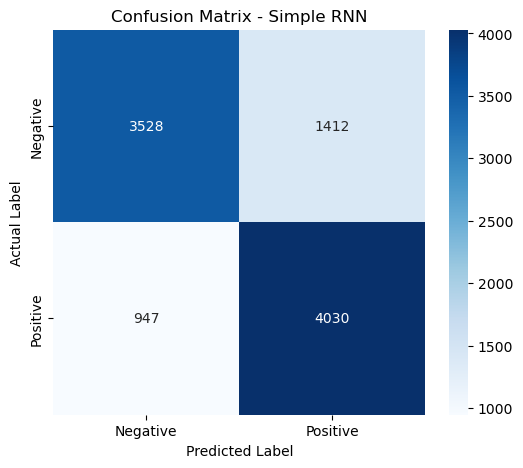

In [19]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(all_labels, all_predictions)

plt.figure(figsize=(6, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Negative", "Positive"],
    yticklabels=["Negative", "Positive"]
)

plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.title("Confusion Matrix - Simple RNN")

plt.show()